# Haapsalu urban blocks

Self-study project: city blocks and block metrics for Haapsalu (Estonia) with BlocksNet,
and a comparison of OpenStreetMap buildings with official Estonian building data.
See `PLAN.md` for the research questions.

## 1. Data

This section downloads every input layer, brings it to the Estonian metric
coordinate system **EPSG:3301 (L-EST97)**, cuts it to the town boundary and saves it to
`data/*.geojson`. Large raw downloads go to `data/raw/` (not in git).
At the end it writes `data/SOURCES.md` and a check map `data/check_map.png`.

### 1.0 Set-up

Libraries, folders and the download date. Every layer is registered in `SOURCES`,
which is used at the end to write `data/SOURCES.md`.

In [1]:
import json
import time
import urllib.request
from datetime import date
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import pandas as pd
from shapely import force_2d

CRS = "EPSG:3301"  # L-EST97, Estonian metric CRS
DATA = Path("data")
RAW = DATA / "raw"
RAW.mkdir(parents=True, exist_ok=True)
TODAY = date.today().isoformat()

ox.settings.use_cache = True
ox.settings.cache_folder = str(RAW / "osmnx_cache")

SOURCES = []  # one dict per saved layer or table


def download(url, path):
    """Download url to path once; later runs reuse the file."""
    path = Path(path)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path


def save_layer(gdf, name, source, url, licence):
    """Save a layer as data/<name>.geojson and register it in SOURCES."""
    gdf = gdf.to_crs(CRS)
    path = DATA / f"{name}.geojson"
    gdf.to_file(path, driver="GeoJSON")
    SOURCES.append(dict(layer=name, file=str(path.as_posix()), source=source, url=url,
                        licence=licence, date=TODAY, features=len(gdf)))
    print(f"{name}: {len(gdf)} features -> {path}")
    return gdf

### 1.1 Town boundary (official)

Source: Maa- ja Ruumiamet, EHAK administrative and settlement division, layer
"Asustusüksused" (settlement units). We take the settlement **Haapsalu linn**
(EHAK code 1692), not the municipality Haapsalu linn, which since 2017 also includes
the former Ridala vald. The file is already in EPSG:3301.

In [2]:
EHAK_URL = "https://s3.pilw.io/rp-kemit-kataster/EHAK/asustusyksus_shp.zip"
ehak_zip = download(EHAK_URL, RAW / "asustusyksus_shp.zip")

settlements = gpd.read_file(f"zip://{ehak_zip.as_posix()}!asustusyksus.shp")
boundary = settlements[settlements["AKOOD"] == "1692"].to_crs(CRS)
assert len(boundary) == 1 and boundary.iloc[0]["ANIMI"] == "Haapsalu linn"
boundary = boundary[["ANIMI", "AKOOD", "ONIMI", "OKOOD", "EKSPORT", "geometry"]]
boundary["EKSPORT"] = boundary["EKSPORT"].astype(str)

save_layer(boundary, "boundary", "Maa- ja Ruumiamet, EHAK settlement units (Asustusüksused), "
           f"Haapsalu linn, AKOOD 1692, export {boundary.iloc[0]['EKSPORT'][:10]}",
           EHAK_URL, "Maa- ja Ruumiamet open data licence (CC BY 4.0 equivalent)")
print(f"Area: {boundary.area.iloc[0] / 1e6:.2f} km²")

area = boundary.geometry.iloc[0]          # boundary polygon in EPSG:3301
area_wgs = boundary.to_crs(4326).geometry.iloc[0]  # the same in WGS84, for OSM queries

boundary: 1 features -> data\boundary.geojson
Area: 11.02 km²


### 1.2 OpenStreetMap layers

Downloaded with `osmnx` for the boundary polygon, using the same tags as the BlocksNet
example `examples/pipeline.ipynb`. Lines and areas (roads, water, land use) are cut
exactly at the boundary. Buildings and schools are **not cut**: an object is kept whole
if its inside point lies in the town, so footprint areas stay correct for the comparison
with the official buildings. Only useful columns are kept.

In [3]:
OSM_URL = "https://www.openstreetmap.org (Overpass API via osmnx)"
OSM_LICENCE = "ODbL 1.0, © OpenStreetMap contributors"


def osm(tags, geom_types, columns, cut=True, attempts=6):
    """Fetch OSM features inside the boundary, keep given geometry types and columns.

    The public Overpass server is sometimes busy, so failed requests are retried
    with a growing pause (30 s, 60 s, 120 s, ...).
    """
    for i in range(attempts):
        try:
            gdf = ox.features_from_polygon(area_wgs, tags)
            break
        except ox._errors.InsufficientResponseError:
            return gpd.GeoDataFrame(columns=["osm_id", *columns, "geometry"], geometry="geometry", crs=CRS)
        except ox._errors.ResponseStatusCodeError as e:
            if i == attempts - 1:
                raise
            print(f"Overpass busy, retry in {30 * 2 ** i} s: {str(e)[:60]}")
            time.sleep(30 * 2 ** i)
    gdf = gdf.reset_index()
    gdf["osm_id"] = gdf["element"] + "/" + gdf["id"].astype(str)
    gdf = gdf[gdf.geom_type.isin(geom_types)]
    gdf = gdf[["osm_id", *[c for c in columns if c in gdf.columns], "geometry"]].to_crs(CRS)
    if cut:
        gdf = gdf.clip(area)
        gdf = gdf[~gdf.is_empty]
    else:
        gdf = gdf[gdf.representative_point().within(area)]
    return gdf.reset_index(drop=True)


LINES = ["LineString", "MultiLineString"]
POLYS = ["Polygon", "MultiPolygon"]

Tags from the BlocksNet example: roads, railways and water. The Haapsalu railway is closed
for passengers, so `railway=rail` may return nothing; then the layer is saved empty.

In [4]:
road_tags = {"highway": ["construction", "crossing", "living_street", "motorway", "motorway_link",
                         "motorway_junction", "pedestrian", "primary", "primary_link", "raceway",
                         "residential", "road", "secondary", "secondary_link", "services", "tertiary",
                         "tertiary_link", "track", "trunk", "trunk_link", "turning_circle",
                         "turning_loop", "unclassified"],
             "service": ["living_street", "emergency_access"]}
water_tags = {"riverbank": True, "reservoir": True, "basin": True, "dock": True, "canal": True,
              "pond": True, "natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"],
              "landuse": "basin", "water": "lake"}

roads = osm(road_tags, LINES, ["highway", "service", "name"])
railways = osm({"railway": "rail"}, LINES, ["railway", "name"])
water = osm(water_tags, POLYS + LINES, ["natural", "water", "waterway", "landuse", "name"])

save_layer(roads, "osm_roads", "OpenStreetMap, highway=* (BlocksNet example tags)", OSM_URL, OSM_LICENCE)
save_layer(railways, "osm_railways", "OpenStreetMap, railway=rail", OSM_URL, OSM_LICENCE)
save_layer(water, "osm_water", "OpenStreetMap, water tags from the BlocksNet example", OSM_URL, OSM_LICENCE);

osm_roads: 697 features -> data\osm_roads.geojson
osm_railways: 4 features -> data\osm_railways.geojson
osm_water: 61 features -> data\osm_water.geojson


Land use (`landuse=*`), buildings (`building=*`, with `building:levels`) and schools
(`amenity=school`).

In [5]:
landuse = osm({"landuse": True}, POLYS, ["landuse", "name"])
buildings_osm = osm({"building": True}, POLYS,
                    ["building", "building:levels", "height", "name", "addr:street", "addr:housenumber"],
                    cut=False)
schools_osm = osm({"amenity": "school"}, POLYS + ["Point"], ["amenity", "name", "isced:level", "capacity"],
                  cut=False)

save_layer(landuse, "osm_landuse", "OpenStreetMap, landuse=*", OSM_URL, OSM_LICENCE)
save_layer(buildings_osm, "osm_buildings", "OpenStreetMap, building=* (whole buildings, inside point in town)",
           OSM_URL, OSM_LICENCE)
save_layer(schools_osm, "osm_schools", "OpenStreetMap, amenity=school", OSM_URL, OSM_LICENCE);

Overpass busy, retry in 30 s: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway T


Overpass busy, retry in 60 s: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway T


osm_landuse: 344 features -> data\osm_landuse.geojson
osm_buildings: 3885 features -> data\osm_buildings.geojson
osm_schools: 5 features -> data\osm_schools.geojson


### 1.3 Official buildings (ETAK + Building Register)

Source: Maa- ja Ruumiamet WFS, layer `etak_tuletis:etak_ehr_hooned`: ETAK building
footprints enriched with Building Register (EHR) data, including the number of floors
`max_korruste_arv`, height, footprint and net floor area, and use. Only the bounding box
of Haapsalu is requested (in pages of 5 000, the server limit), then buildings whose
inside point lies in the town are kept. Heights in the geometry (Z) are dropped.

In [6]:
WFS = "https://gsavalik.envir.ee/geoserver/etak_tuletis/wfs"
xmin, ymin, xmax, ymax = boundary.total_bounds
pages, start = [], 0
while True:
    url = (f"{WFS}?service=WFS&version=2.0.0&request=GetFeature&typeNames=etak_tuletis:etak_ehr_hooned"
           f"&srsName=EPSG:3301&outputFormat=application/json&sortBy=fid&count=5000&startIndex={start}"
           f"&bbox={xmin:.0f},{ymin:.0f},{xmax:.0f},{ymax:.0f},EPSG:3301")
    with urllib.request.urlopen(url) as r:
        page = json.load(r)
    pages += page["features"]
    start += len(page["features"])
    if len(page["features"]) < 5000:
        break

(RAW / "etak_ehr_hooned_bbox.geojson").write_text(
    json.dumps({"type": "FeatureCollection", "features": pages}), encoding="utf-8")
buildings_off = gpd.GeoDataFrame.from_features(pages, crs=CRS)
buildings_off["geometry"] = force_2d(buildings_off.geometry)
print(f"In bounding box: {len(buildings_off)}")
buildings_off = buildings_off[buildings_off.representative_point().within(area)].reset_index(drop=True)

save_layer(buildings_off, "official_buildings",
           "Maa- ja Ruumiamet, WFS etak_tuletis:etak_ehr_hooned (ETAK buildings with EHR data), "
           "Haapsalu bounding box, inside point in town",
           WFS, "Maa- ja Ruumiamet open data licence (CC BY 4.0 equivalent)");

In bounding box: 4560


official_buildings: 3941 features -> data\official_buildings.geojson


### 1.4 Statistics Estonia (census 2021)

Two tables from the Statistics Estonia database (PxWeb API), both for the settlement
unit Haapsalu linn (code `005601841692L5`), state on 31 December 2021:

- **RL21003**: population by place of residence (settlement), sex and age. Gives the total
  population and the number of children aged 7–18.
- **RL21807**: average area of dwelling per inhabitant in occupied conventional dwellings.
  Lääne county and the whole country are kept for comparison.

In [7]:
STAT = "https://andmed.stat.ee/api/v1/en/stat/"
T_POP = "rahvaloendus/rel2021/rahvastiku_paiknemine/elukoht-ja-soo-vanusjaotus/RL21003.px"
T_AREA = "rahvaloendus/rel2021/elamistingimused/RL21807.px"
HAAPSALU = "005601841692L5"


def pxweb(table, selection):
    body = {"query": [{"code": k, "selection": {"filter": "item", "values": v}} for k, v in selection.items()],
            "response": {"format": "json-stat2"}}
    req = urllib.request.Request(STAT + table, json.dumps(body).encode(), {"Content-Type": "application/json"})
    with urllib.request.urlopen(req) as r:
        return json.load(r)


with urllib.request.urlopen(STAT + T_POP) as r:
    ages = {v: t for v, t in zip(*[(x["values"], x["valueTexts"]) for x in json.load(r)["variables"]
                                   if x["code"] == "Vanus"][0])}
pop = pxweb(T_POP, {"Sugu": ["1"], "Elukoht": [HAAPSALU], "Vanus": list(ages)})
by_age = dict(zip(pop["dimension"]["Vanus"]["category"]["index"], pop["value"]))
population = by_age["1"]  # "Age total"
children_7_18 = sum(n for code_, n in by_age.items() if ages[code_].isdigit() and 7 <= int(ages[code_]) <= 18)

places = {"1": "Estonia", "00560000000000": "Lääne county", "00560184000001": "Haapsalu municipality",
          HAAPSALU: "Haapsalu linn (settlement)"}
area_tab = pxweb(T_AREA, {"Elukoht": list(places), "Rahvus": ["1"], "Leibkonna suurus": ["1"],
                          "Näitaja": ["1"], "Sugu": ["1"], "Vanus": ["1"]})
idx = area_tab["dimension"]["Elukoht"]["category"]["index"]
area_per_person = {places[k]: area_tab["value"][i] for k, i in idx.items()}

statistics = {
    "population_haapsalu_linn_2021": population,
    "children_7_18_haapsalu_linn_2021": children_7_18,
    "dwelling_area_per_inhabitant_m2_2021": area_per_person,
    "tables": {"RL21003": STAT + T_POP, "RL21807": STAT + T_AREA},
    "reference_date": "2021-12-31", "download_date": TODAY,
}
(DATA / "statistics.json").write_text(json.dumps(statistics, indent=2, ensure_ascii=False), encoding="utf-8")
SOURCES.append(dict(layer="statistics", file="data/statistics.json",
                    source="Statistics Estonia, census 2021, tables RL21003 and RL21807",
                    url=STAT, licence="Statistics Estonia terms of use (free use with source reference)",
                    date=TODAY, features=None))
statistics

{'population_haapsalu_linn_2021': 9595,
 'children_7_18_haapsalu_linn_2021': 1188,
 'dwelling_area_per_inhabitant_m2_2021': {'Estonia': 23.5,
  'Lääne county': 25.1,
  'Haapsalu municipality': 24.1,
  'Haapsalu linn (settlement)': 22.7},
 'tables': {'RL21003': 'https://andmed.stat.ee/api/v1/en/stat/rahvaloendus/rel2021/rahvastiku_paiknemine/elukoht-ja-soo-vanusjaotus/RL21003.px',
  'RL21807': 'https://andmed.stat.ee/api/v1/en/stat/rahvaloendus/rel2021/elamistingimused/RL21807.px'},
 'reference_date': '2021-12-31',
 'download_date': '2026-10-30'}

### 1.5 Schools: number of students (EHIS)

Source: Estonian Education Information System (EHIS) open data, service
`opilastearvud` (student numbers per school and grade) on 1 October 2026. The service
gives the number of students, not the design capacity, so the number of students is used
as the school capacity. Students are summed over grades; the separate count
"tugi olemas" (students with support) is a subset and is not added. Schools are selected
by their legal address in the municipality Haapsalu linn; whether each one lies inside
the settlement is checked on the map later. The vocational school is listed but marked,
because it is not a general school for ages 7–18.

In [8]:
EHIS_DATE = "01.10.2026"
EHIS_URL = f"http://enda.ehis.ee/avaandmed/rest/opilastearvud/{EHIS_DATE}/JSON"
ehis_raw = download(EHIS_URL, RAW / f"ehis_opilastearvud_{EHIS_DATE}.json")
records = json.loads(ehis_raw.read_text(encoding="utf-8"))["body"]["opilastearvud"]["opilastearv"]

rows = []
for r in records:
    addr = r.get("juriidilineAadress", {})
    if addr.get("kov") != "Haapsalu linn" or r.get("tyyp") not in ("põhikool või gümnaasium", "kutseõppeasutus"):
        continue
    grades = [x for x in r["arvud"] if "klassVoiTase" in x]
    rows.append(dict(name=r["nimetus"], reg_nr=r["regNr"], ehis_id=r["koolId"], type=r.get("tyyp"),
                     subtype=r.get("alamTyyp", ""), address=addr.get("aadress", "").replace("|", " ").split(),
                     postcode=addr.get("sihtnumber"), students=sum(int(x["arv"]) for x in grades),
                     general_school=r.get("tyyp") == "põhikool või gümnaasium"))
ehis = pd.DataFrame(rows)
ehis["address"] = ehis["address"].str.join(" ")
ehis = ehis.sort_values("students", ascending=False).reset_index(drop=True)
ehis.to_csv(DATA / "ehis_schools.csv", index=False)
SOURCES.append(dict(layer="ehis_schools", file="data/ehis_schools.csv",
                    source=f"EHIS open data, service opilastearvud, {EHIS_DATE}, legal address in Haapsalu linn municipality",
                    url=EHIS_URL, licence="EHIS open data (andmed.eesti.ee); licence to be confirmed",
                    date=TODAY, features=len(ehis)))
ehis

,name,reg_nr,ehis_id,type,subtype,address,postcode,students,general_school
0,Haapsalu Põhikool,75012966,388,põhikool või gümnaasium,põhikool,Lihula mnt 12,90507,598,True
1,Haapsalu Kutsehariduskeskus,70003796,51,kutseõppeasutus,,Ehitajate tee 3,90401,426,False
2,Läänemaa Ühisgümnaasium,75038167,3551,põhikool või gümnaasium,gümnaasium,F. J. Wiedemanni tn 15,90503,304,True
3,Haapsalu Linna Algkool,75012952,387,põhikool või gümnaasium,põhikool,Ehte tn 14,90502,282,True
4,Uuemõisa Lasteaed-Algkool,75022485,566,põhikool või gümnaasium,lasteaed-põhikool,Lossi tänav 4,90401,153,True
5,Ridala Põhikool,75022508,568,põhikool või gümnaasium,lasteaed-põhikool,Kooli tn 4,90402,135,True
6,Haapsalu Viigi Kool,70005660,814,põhikool või gümnaasium,põhikool,Suur-Mere tn 17,90502,89,True
7,Haapsalu Montessori Kool,80650545,2162466,põhikool või gümnaasium,põhikool,Jaama tn 15,90507,8,True


### 1.6 Summary

Number of features per layer, and how many buildings have a number of floors:
`building:levels` in OSM, `max_korruste_arv` in the official layer.

In [9]:
summary = pd.DataFrame([s for s in SOURCES if s["features"] is not None])[["layer", "features"]]
osm_levels = pd.to_numeric(buildings_osm["building:levels"], errors="coerce") if "building:levels" in buildings_osm else pd.Series(dtype=float)
floors = pd.DataFrame([
    dict(layer="osm_buildings", buildings=len(buildings_osm), with_floors=int(osm_levels.notna().sum())),
    dict(layer="official_buildings", buildings=len(buildings_off),
         with_floors=int(buildings_off["max_korruste_arv"].notna().sum())),
])
floors["share_%"] = (100 * floors["with_floors"] / floors["buildings"]).round(1)
display(summary)
display(floors)

,layer,features
0,boundary,1
1,osm_roads,697
2,osm_railways,4
3,osm_water,61
4,osm_landuse,344
5,osm_buildings,3885
6,osm_schools,5
7,official_buildings,3941
8,ehis_schools,8


,layer,buildings,with_floors,share_%
0,osm_buildings,3885,140,3.6
1,official_buildings,3941,2982,75.7


### 1.7 `data/SOURCES.md`

One row per layer or table: source, URL, licence, download date and number of features.

In [10]:
lines = ["# Data sources", "",
         "Generated by `notebook.ipynb`, section 1. All layers are in EPSG:3301 (L-EST97).", "",
         "| Layer | File | Source | URL | Licence | Downloaded | Features |",
         "| --- | --- | --- | --- | --- | --- | --- |"]
for s in SOURCES:
    n = "" if s["features"] is None else s["features"]
    lines.append(f"| {s['layer']} | `{s['file']}` | {s['source']} | {s['url']} | {s['licence']} | {s['date']} | {n} |")
lines += ["", "Number of floors in building layers:", "",
          "| Layer | Buildings | With floors | Share, % |", "| --- | --- | --- | --- |"]
lines += [f"| {r.layer} | {r.buildings} | {r.with_floors} | {r._4} |" for r in floors.itertuples()]
(DATA / "SOURCES.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

# Data sources

Generated by `notebook.ipynb`, section 1. All layers are in EPSG:3301 (L-EST97).

| Layer | File | Source | URL | Licence | Downloaded | Features |
| --- | --- | --- | --- | --- | --- | --- |
| boundary | `data/boundary.geojson` | Maa- ja Ruumiamet, EHAK settlement units (Asustusüksused), Haapsalu linn, AKOOD 1692, export 2026-09-02 | https://s3.pilw.io/rp-kemit-kataster/EHAK/asustusyksus_shp.zip | Maa- ja Ruumiamet open data licence (CC BY 4.0 equivalent) | 2026-10-30 | 1 |
| osm_roads | `data/osm_roads.geojson` | OpenStreetMap, highway=* (BlocksNet example tags) | https://www.openstreetmap.org (Overpass API via osmnx) | ODbL 1.0, © OpenStreetMap contributors | 2026-10-30 | 697 |
| osm_railways | `data/osm_railways.geojson` | OpenStreetMap, railway=rail | https://www.openstreetmap.org (Overpass API via osmnx) | ODbL 1.0, © OpenStreetMap contributors | 2026-10-30 | 4 |
| osm_water | `data/osm_water.geojson` | OpenStreetMap, water tags from the BlocksNet example | https:

### 1.8 Check map

Boundary, roads, water and both building layers, side by side, saved to
`data/check_map.png` for a visual check before building blocks.

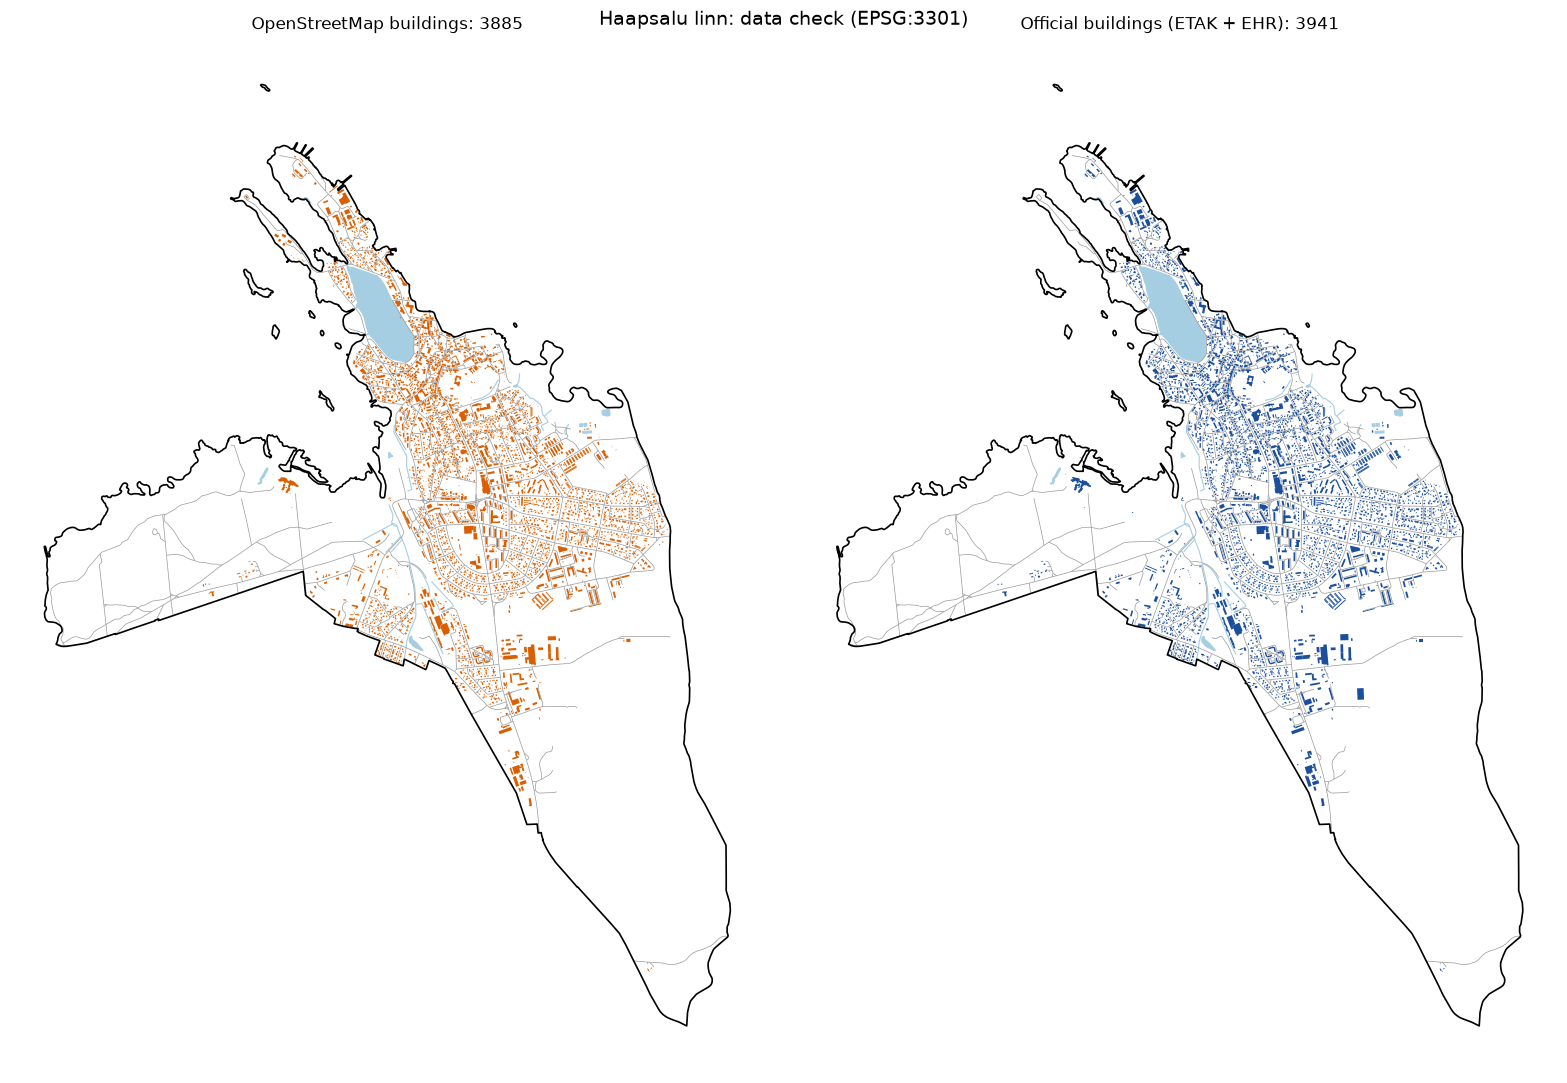

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 11), sharex=True, sharey=True)
for ax, (title, b, colour) in zip(axes, [("OpenStreetMap buildings", buildings_osm, "#d95f02"),
                                         ("Official buildings (ETAK + EHR)", buildings_off, "#1b4f9c")]):
    water.plot(ax=ax, color="#a6cee3", edgecolor="#a6cee3", linewidth=0.8)
    roads.plot(ax=ax, color="#999999", linewidth=0.5)
    b.plot(ax=ax, color=colour, linewidth=0)
    boundary.boundary.plot(ax=ax, color="black", linewidth=1.2)
    ax.set_title(f"{title}: {len(b)}")
    ax.set_axis_off()
fig.suptitle("Haapsalu linn: data check (EPSG:3301)", fontsize=14)
fig.tight_layout()
fig.savefig(DATA / "check_map.png", dpi=150)
plt.show()